# CSI CNN pilot: EDA, preprocessing, training, and evaluation

This notebook walks through the **executed `pilot_v1` experiment** on the same session as `02_simple_eda.ipynb`. It shows the saved data checks, training examples, preprocessing choices, model selection, and held-out results.

By default, **Run All reads saved results**. It does not train again or replace checkpoints. Set `RERUN_PIPELINE = True` below to execute the stages into a separate `artifacts/notebook_rerun/` folder. The implementation lives alongside this notebook in `data_pipeline.py`, `modeling.py`, and `reporting.py`.

The operator manually marked observed movement. We use that recorded action timestamp as the window anchor; it is not assumed to identify impact to millisecond accuracy. This experiment uses one fixed four-second window per attempt. **Shifted or sliding windows have not been implemented or evaluated.**

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

FOLDER = next(
    candidate
    for parent in (Path.cwd(), *Path.cwd().parents)
    for candidate in (parent, parent / "notebooks/03_cnn_baseline")
    if (candidate / "modeling.py").is_file()
    and (candidate / "config.json").is_file()
    and (candidate / "vendor/provenance.json").is_file()
)
CONFIG = json.loads((FOLDER / "config.json").read_text())
RERUN_PIPELINE = False
RERUN_DIR = FOLDER / "artifacts/notebook_rerun"
RESULTS = RERUN_DIR if RERUN_PIPELINE else FOLDER / "results/pilot_v1"
PYTHON = FOLDER / ".venv/bin/python"

pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")


def run_stage(stage: str) -> None:
    """Run a stage only when the explicit rerun switch is enabled."""
    if RERUN_PIPELINE:
        if not PYTHON.exists():
            raise FileNotFoundError("From this folder, first run: uv sync --frozen --extra notebook")
        subprocess.run(
            [str(PYTHON), "run.py", "--stage", stage, "--output", str(RERUN_DIR)],
            cwd=FOLDER, check=True,
        )
    else:
        print(f"{stage}: showing saved pilot_v1 outputs")


def show_figure(name: str, width: int = 1100) -> None:
    """Display an exported figure from the active experiment."""
    display(Image(filename=str(RESULTS / "figures" / name), width=width))


print(f"Experiment folder: {FOLDER}")
print(f"Results: {RESULTS}")
print(f"Run preprocessing/training/evaluation again: {RERUN_PIPELINE}")

Experiment folder: /home/khaelano/Projects/radio-fall-detection/notebooks/03_cnn_baseline
Results: /home/khaelano/Projects/radio-fall-detection/notebooks/03_cnn_baseline/results/pilot_v1
Run preprocessing/training/evaluation again: False


## 1. Configuration and reproducibility

We compare amplitude, raw phase, calibrated phase, calibrated phase change over 100 ms, and a smoothed version of that change. The split seed, three training seeds, window length, and training settings were fixed before the reported test evaluation.

A rerun repeats the same pilot on the same test cohort. It does not provide a new independent test set. Keep later tuning decisions within training and validation data.

In [2]:
display(pd.Series(CONFIG, name="value").to_frame())

,value
session_path,../../data/raw/sessions/20261026T174653764289Z
receivers,"[rx-1, rx-2]"
window_seconds,4.000
bin_hz,25
lag_seconds,0.100
smoothing_bins,3
minimum_coverage,0.700
split_seed,20261028
training_seeds,"[17, 29, 43]"
max_epochs,40


## 2. Prepare the data and freeze the split

`prepare` resolves accepted attempts and reviewed labels, checks phase timestamps, and assigns whole activity/direction scenarios to training, validation, or testing. All repetitions, retakes, and both receivers stay together. The membership is frozen before signal quality is checked; excluding a recording does not redraw the split.

Raw files are read only. Their SHA-256 hashes, preparation-code hashes, array hash, and split hash are recorded in `manifest.json`. Large derived arrays and checkpoints stay under ignored `artifacts/`.

In [3]:
run_stage("prepare")
manifest = json.loads((RESULTS / "manifest.json").read_text())
trials = pd.read_csv(RESULTS / "trials.csv")
inventory = pd.read_csv(RESULTS / "inventory.csv")
quality = pd.read_csv(RESULTS / "quality.csv")

assert trials.groupby("scenario_id")["split"].nunique().eq(1).all()
assert trials.groupby("trial_ordinal")["split"].nunique().eq(1).all()
assert trials["attempt_id"].is_unique

print(f"Attempts in inventory: {len(inventory)}")
print(f"Retained attempts: {len(trials)}")
print(f"Preparation exclusions after scope: {manifest['attempts_excluded_after_scope']}")
print(f"Participant: {', '.join(trials['participant_id'].unique())}")
display(pd.crosstab(trials["label"], trials["split"]))
display(trials[["attempt_id", "label", "scenario_id", "split"]].head(12))

prepare: showing saved pilot_v1 outputs
Attempts in inventory: 171
Retained attempts: 154
Preparation exclusions after scope: 0
Participant: akmal


split,test,train,validation
label,,,
sit_to_fall,4,10,4
sit_to_stand,2,4,2
sit_to_walk,6,20,6
stand_to_fall,6,20,6
walk_to_fall,6,20,6
walk_to_sit,6,20,6


,attempt_id,label,scenario_id,split
0,001/01,walk_to_fall,walk-to-fall__start_front__end_front,test
1,002/01,walk_to_fall,walk-to-fall__start_front__end_front,test
2,003/01,walk_to_fall,walk-to-fall__start_front__end_left,test
3,004/01,walk_to_fall,walk-to-fall__start_front__end_left,test
4,005/01,walk_to_fall,walk-to-fall__start_front__end_right,train
5,006/01,walk_to_fall,walk-to-fall__start_front__end_right,train
6,007/01,walk_to_fall,walk-to-fall__start_front__end_back,train
7,008/01,walk_to_fall,walk-to-fall__start_front__end_back,train
8,009/01,walk_to_fall,walk-to-fall__start_left__end_front,train
9,010/01,walk_to_fall,walk-to-fall__start_left__end_front,train


## 3. EDA: coverage, activity duration, and training signals

We check how many examples each activity contributes, whether both receivers provide enough valid data, and how long the manually marked action interval lasts. The signal galleries use the first training example of each activity, selected by identity rather than signal strength. Validation and test signals were not inspected to choose the input settings.

eda: showing saved pilot_v1 outputs


,rx-1_coverage,rx-2_coverage
count,154.000,154.000
mean,0.995,0.995
std,0.002,0.004
min,0.982,0.963
25%,0.996,0.995
50%,0.996,0.996
75%,0.996,0.996
max,0.996,0.996


Read/quality exclusions: 0


,recordings
rx-1_time_source,
receiver callback → host (USB affine fit),154


,recordings
rx-2_time_source,
receiver callback → host (USB affine fit),154


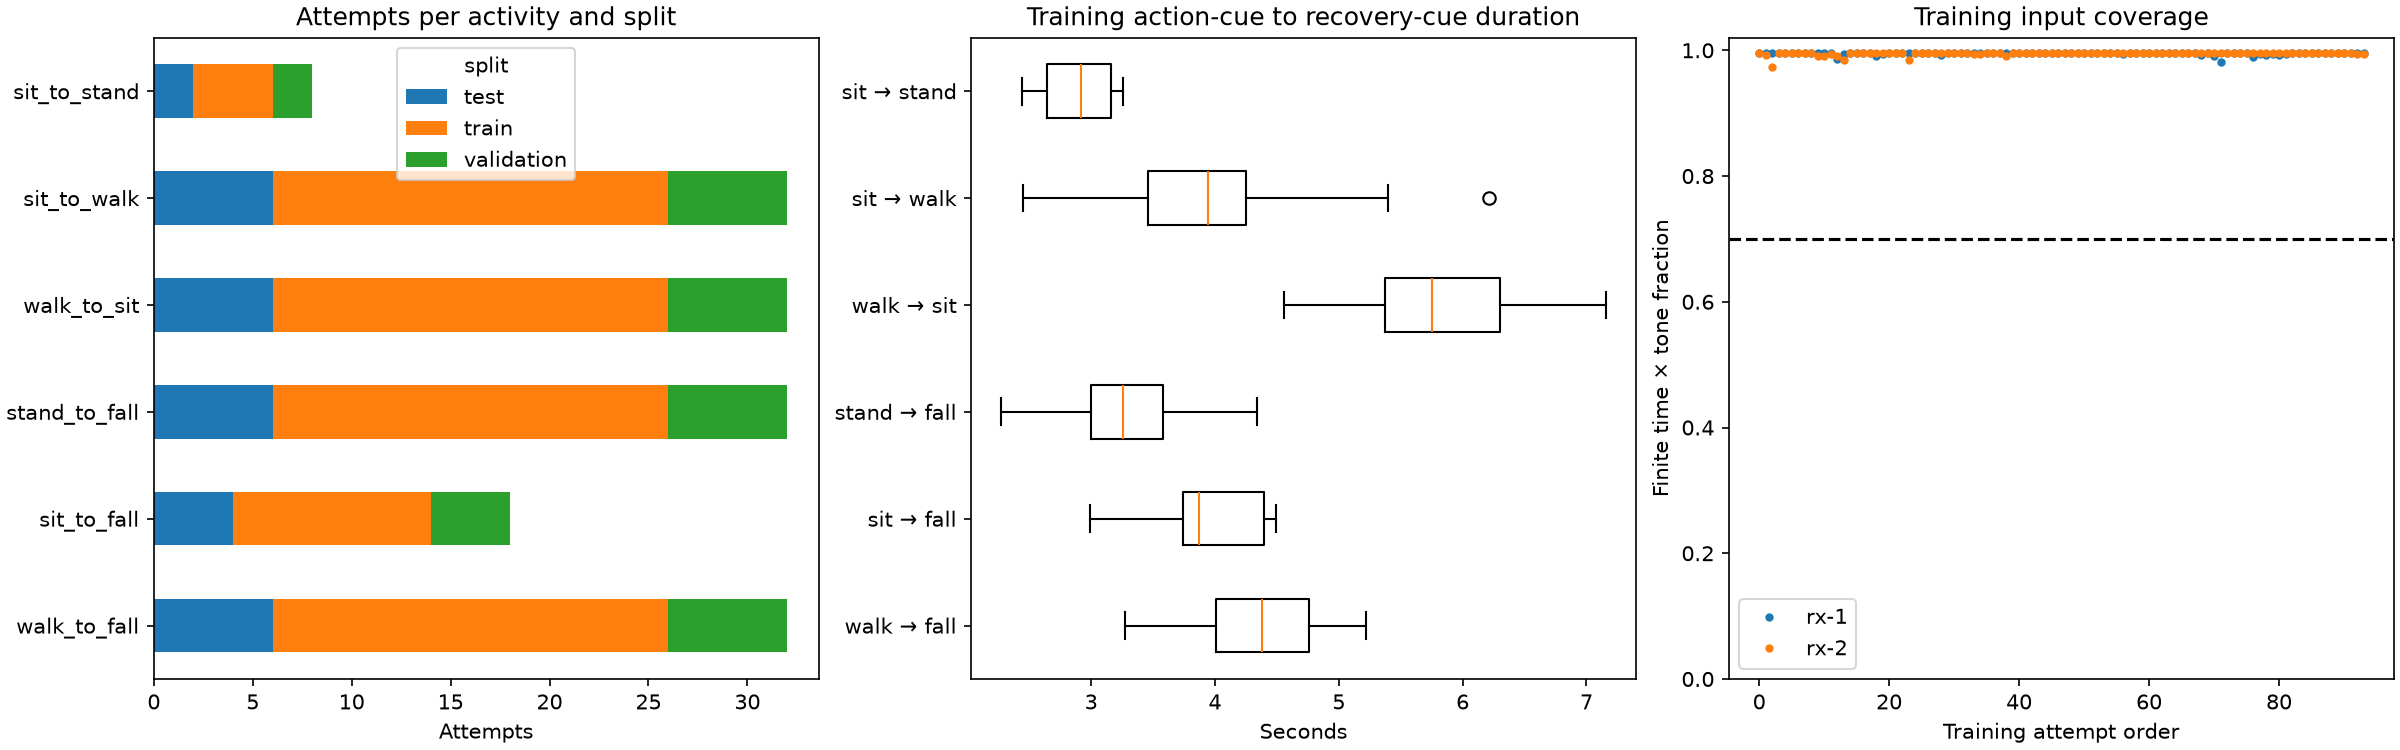

In [4]:
run_stage("eda")
coverage_columns = [f"{receiver}_coverage" for receiver in CONFIG["receivers"]]
display(quality[coverage_columns].describe())
print("Read/quality exclusions:", quality["read_error"].fillna("").ne("").sum())
for receiver in CONFIG["receivers"]:
    display(quality[f"{receiver}_time_source"].value_counts().rename("recordings").to_frame())
show_figure("eda_inventory.png")

The next plots retain time and individual subcarriers. They show amplitude and 100 ms phase change for both receivers. Similar-looking activity examples do not by themselves establish whether a classifier will succeed or fail.

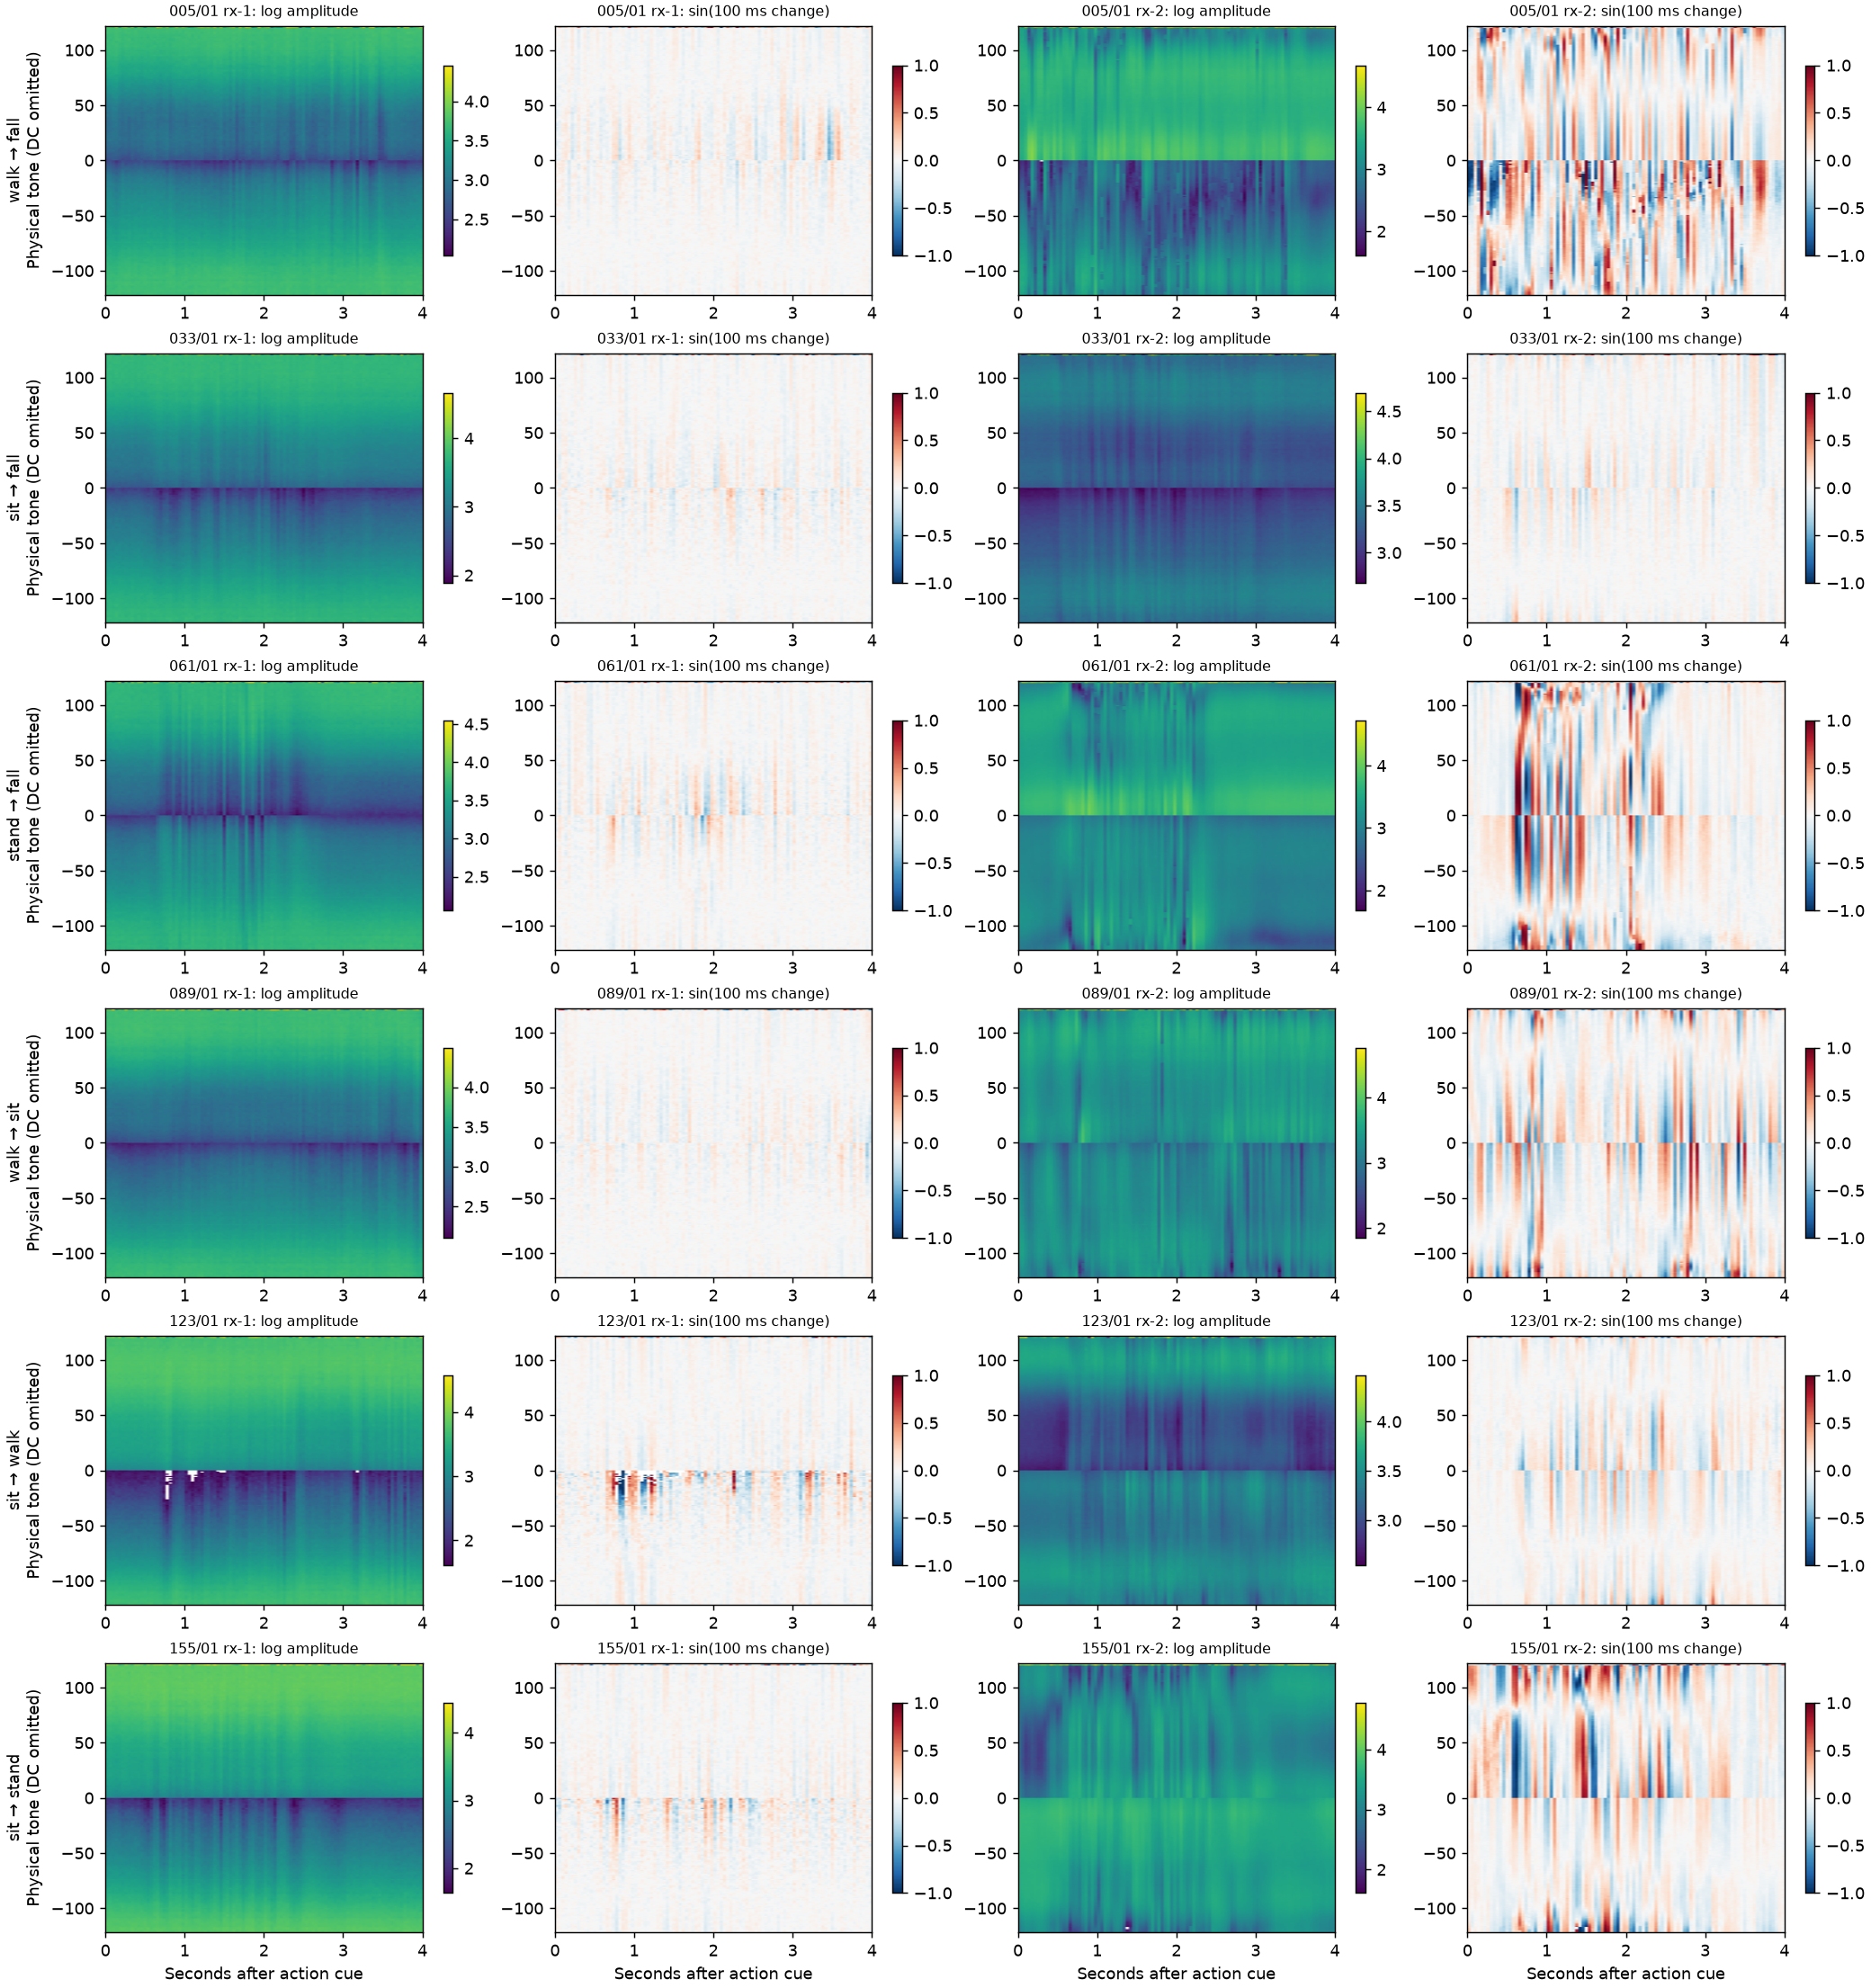

In [5]:
show_figure("eda_training_examples.png")

Calibrated phase is represented by sine and cosine, so values near −π and +π do not appear artificially far apart. The following gallery shows the same predetermined training examples.

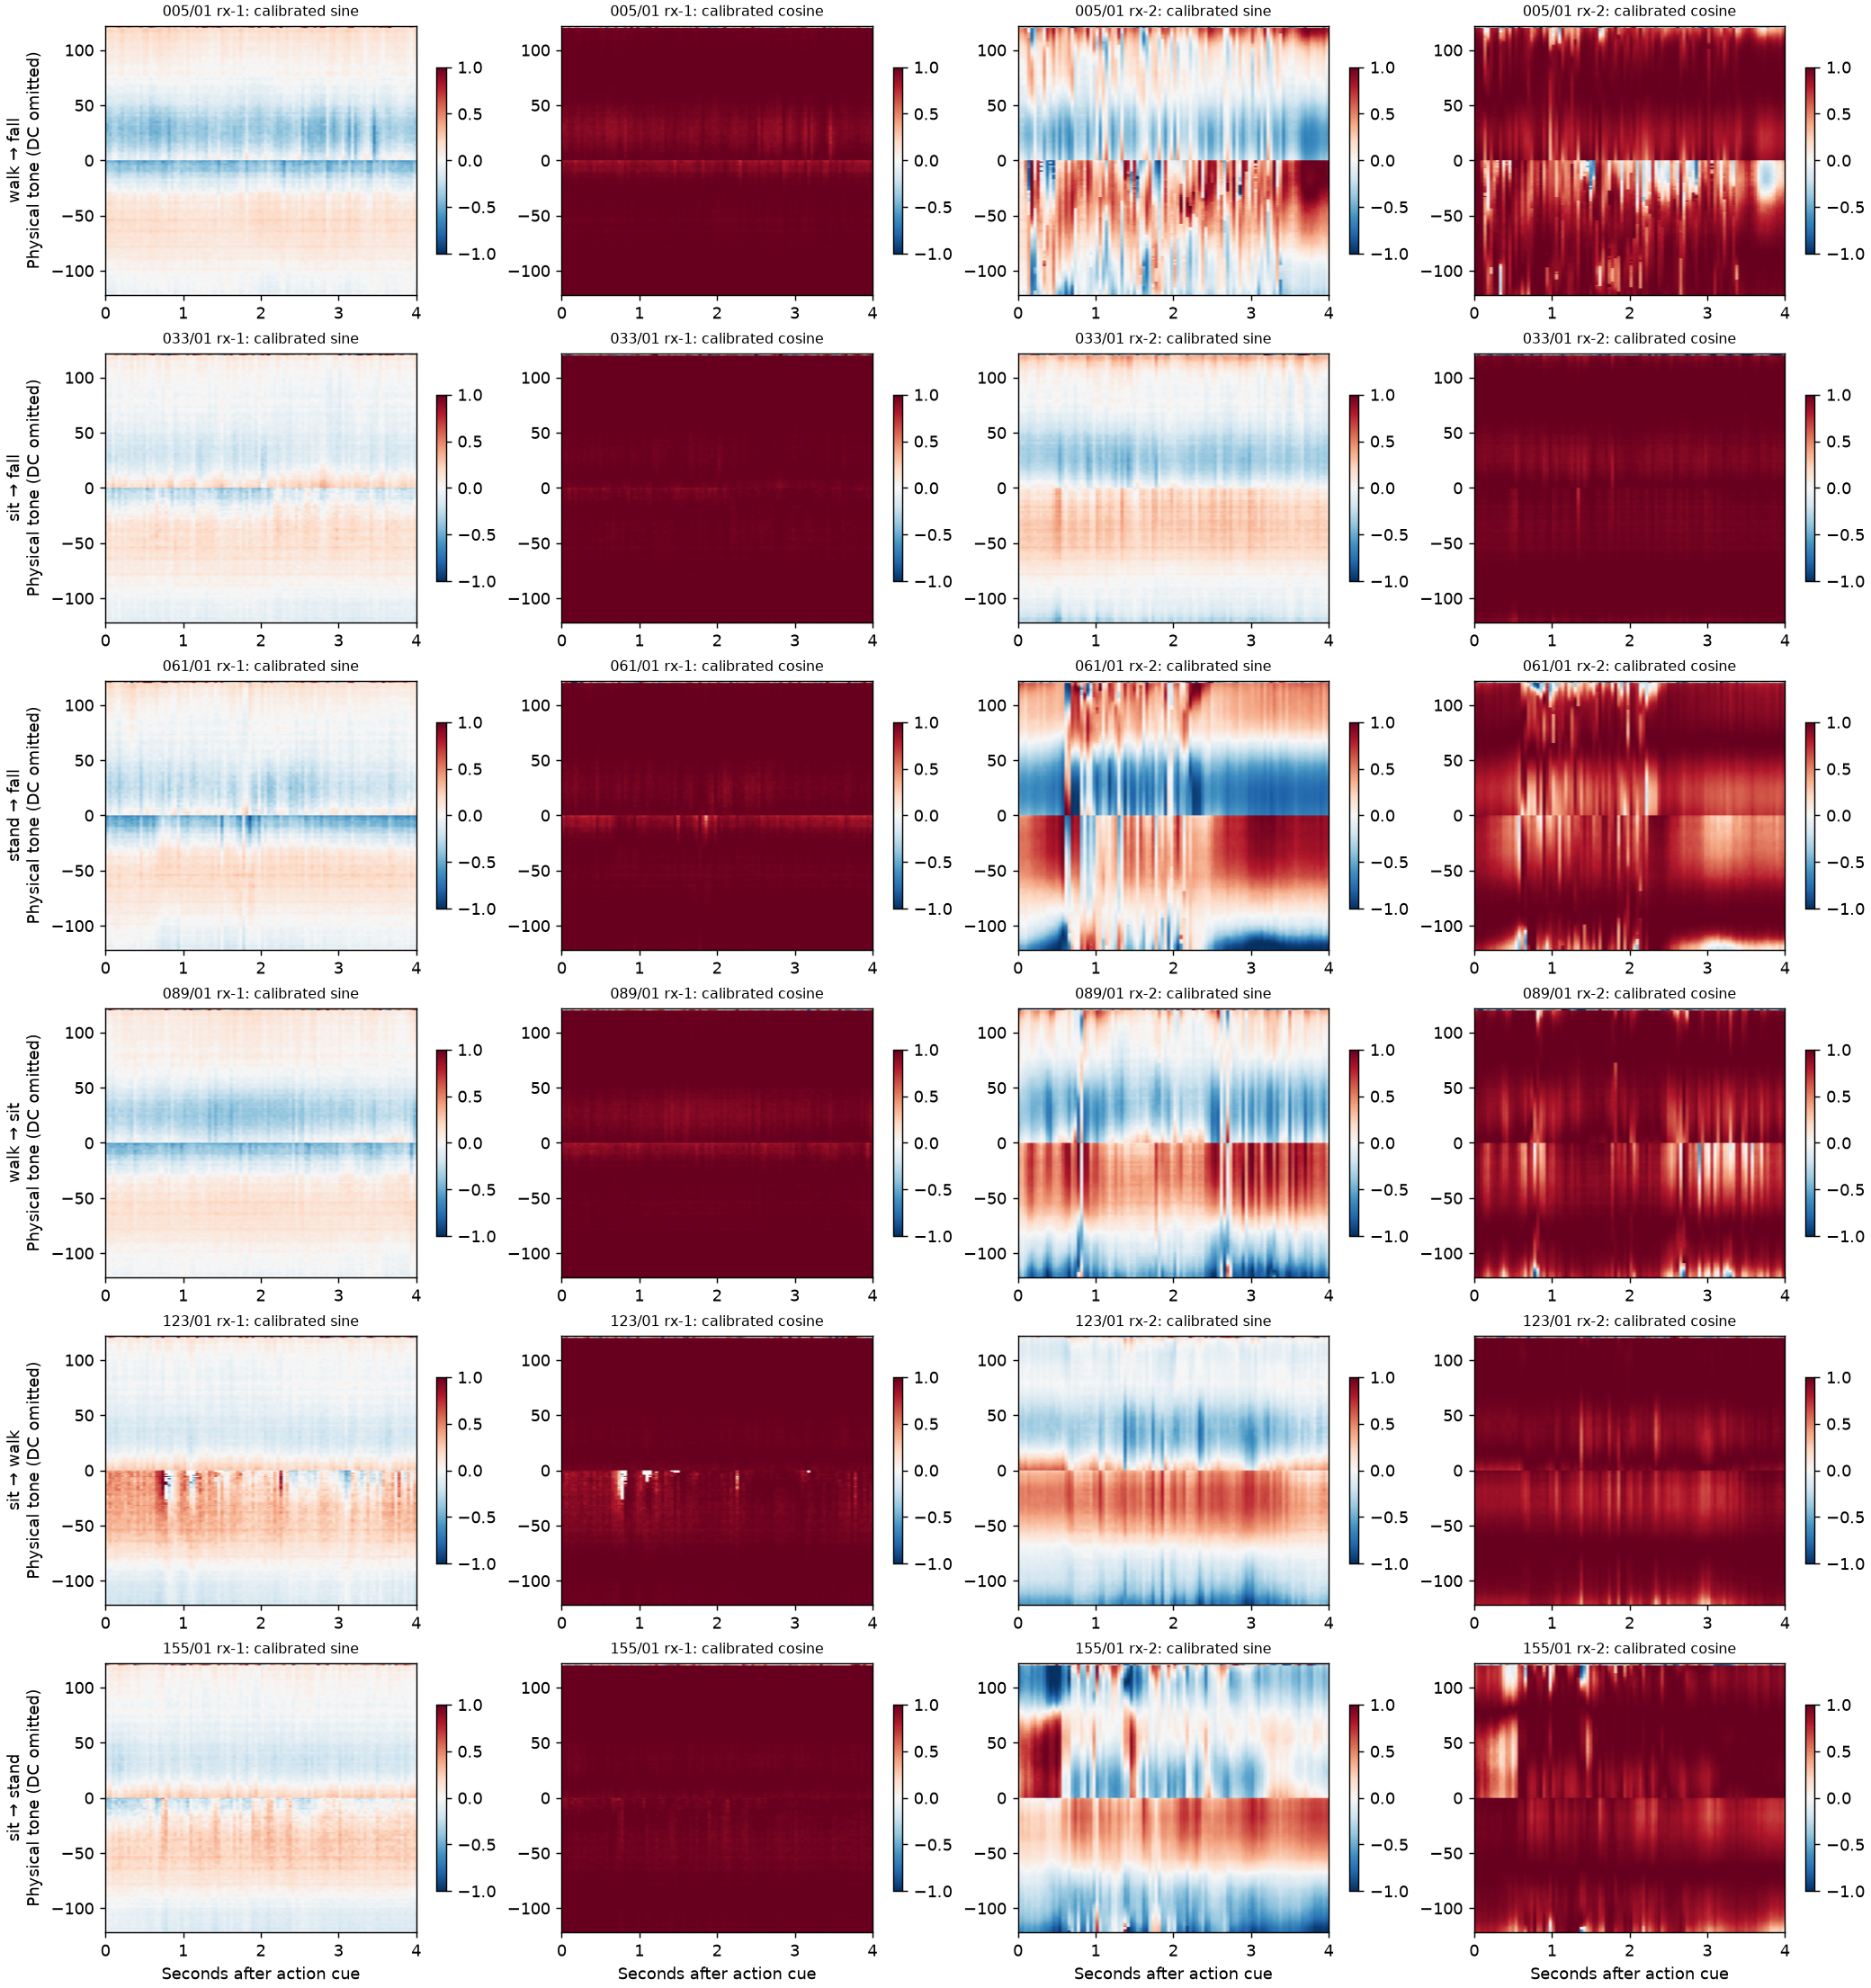

In [6]:
show_figure("eda_calibrated_training_examples.png")

## 4. What preprocessing gives the CNN

For each attempt:

1. Decode the transmitter's HE20 CSI using the pinned canonical decoder and align receiver clocks to the recorded event timeline.
2. Retain 242 valid physical tones, excluding only the three structural DC slots. Low-amplitude or otherwise invalid values remain missing.
3. Extract **[0, 4) seconds after the manual action mark**, and average packets within 100 bins at 25 Hz, separately for each tone and receiver. No interpolation fills empty bins.
4. Represent phase and phase change with sine/cosine components. The smoothing ablation averages three adjacent time bins, preserving missing center bins.
5. Fit channel/tone normalization using training attempts only. Replace missing values with zero after normalization and append their validity masks.

Both receivers become feature channels in one example. A short action may include recovery in the window; a longer action may be truncated. The experiment has not checked whether moving the window earlier or later improves robustness.

In [7]:
shape_rows = []
for name in CONFIG["representations"]:
    signal_channels = len(CONFIG["receivers"]) * (1 if name == "amplitude" else 2)
    shape_rows.append({
        "representation": name,
        "signal_channels": signal_channels,
        "mask_channels": signal_channels,
        "time_bins": round(CONFIG["window_seconds"] * CONFIG["bin_hz"]),
        "subcarriers": 242,
    })
display(pd.DataFrame(shape_rows))

# When local prepared arrays exist, inspect their actual shapes without changing them.
array_folder = RESULTS if RERUN_PIPELINE else FOLDER / "artifacts/pilot_v1"
if (array_folder / "dataset.npz").exists():
    with np.load(array_folder / "dataset.npz") as dataset:
        for name in CONFIG["representations"]:
            values = dataset[name]
            print(name, values.shape, "finite fraction:", round(float(np.isfinite(values).mean()), 4))
else:
    print("Large local arrays are unavailable; saved tables and figures remain readable.")

,representation,signal_channels,mask_channels,time_bins,subcarriers
0,amplitude,2,2,100,242
1,raw_phase,4,4,100,242
2,calibrated_phase,4,4,100,242
3,phase_change,4,4,100,242
4,phase_change_smoothed,4,4,100,242


amplitude (154, 2, 100, 242) finite fraction: 0.9953


raw_phase (154, 4, 100, 242) finite fraction: 0.9953


calibrated_phase (154, 4, 100, 242) finite fraction: 0.9953


phase_change (154, 4, 100, 242) finite fraction: 0.9948


phase_change_smoothed (154, 4, 100, 242) finite fraction: 0.9948


## 5. CNN training and validation selection

The CNN learns local patterns across time and frequency using three convolution/ReLU stages with 8, 16, and 32 channels. Global average pooling, dropout, and a binary output follow. No tone average or PCA is applied before these learned convolutions.

Training uses class-weighted binary cross entropy, AdamW, and early stopping based on validation loss. Each representation is fitted with three seeds, and their probabilities are averaged. Validation balanced accuracy selects the representation, with ROC AUC as a tie-breaker. The decision threshold remains 0.5. Test scores do not select epochs or the representation.

In [8]:
run_stage("train")
selection = json.loads((RESULTS / "selection.json").read_text())
validation = pd.read_csv(RESULTS / "validation_candidates.csv")
print("Selected representation:", selection["selected_representation"])
print("Training seeds:", selection["seeds"])
print("Threshold:", selection["threshold"])
display(validation[["representation", "balanced_accuracy", "fall_recall", "specificity", "roc_auc"]])

train: showing saved pilot_v1 outputs
Selected representation: calibrated_phase
Training seeds: [17, 29, 43]
Threshold: 0.5


,representation,balanced_accuracy,fall_recall,specificity,roc_auc
0,amplitude,0.772,0.688,0.857,0.862
1,raw_phase,0.500,1.000,0.000,0.446
2,calibrated_phase,1.000,1.000,1.000,1.000
3,phase_change,0.634,0.625,0.643,0.714
4,phase_change_smoothed,0.594,0.688,0.500,0.674


## 6. Held-out evaluation

The test set holds out complete scenarios from this session. The model is compared with a majority prediction, logistic regression on simple signal summaries, and logistic regression that sees missingness summaries without signal values. The last baseline checks whether recording quality itself carries label information.

evaluate: showing saved pilot_v1 outputs
Test attempts: 30; test scenarios: 15


,accuracy,balanced_accuracy,fall_recall,specificity,fall_f1,roc_auc,tn,fp,fn,tp
cnn,0.933,0.929,1.000,0.857,0.941,0.991,12.000,2.000,0.000,16.000
summary_logistic,0.867,0.862,0.938,0.786,0.882,0.973,11.000,3.000,1.000,15.000
quality_only,0.633,0.647,0.438,0.857,0.560,0.844,12.000,2.000,9.000,7.000
majority,0.533,0.500,1.000,0.000,0.696,0.500,0.000,14.000,0.000,16.000


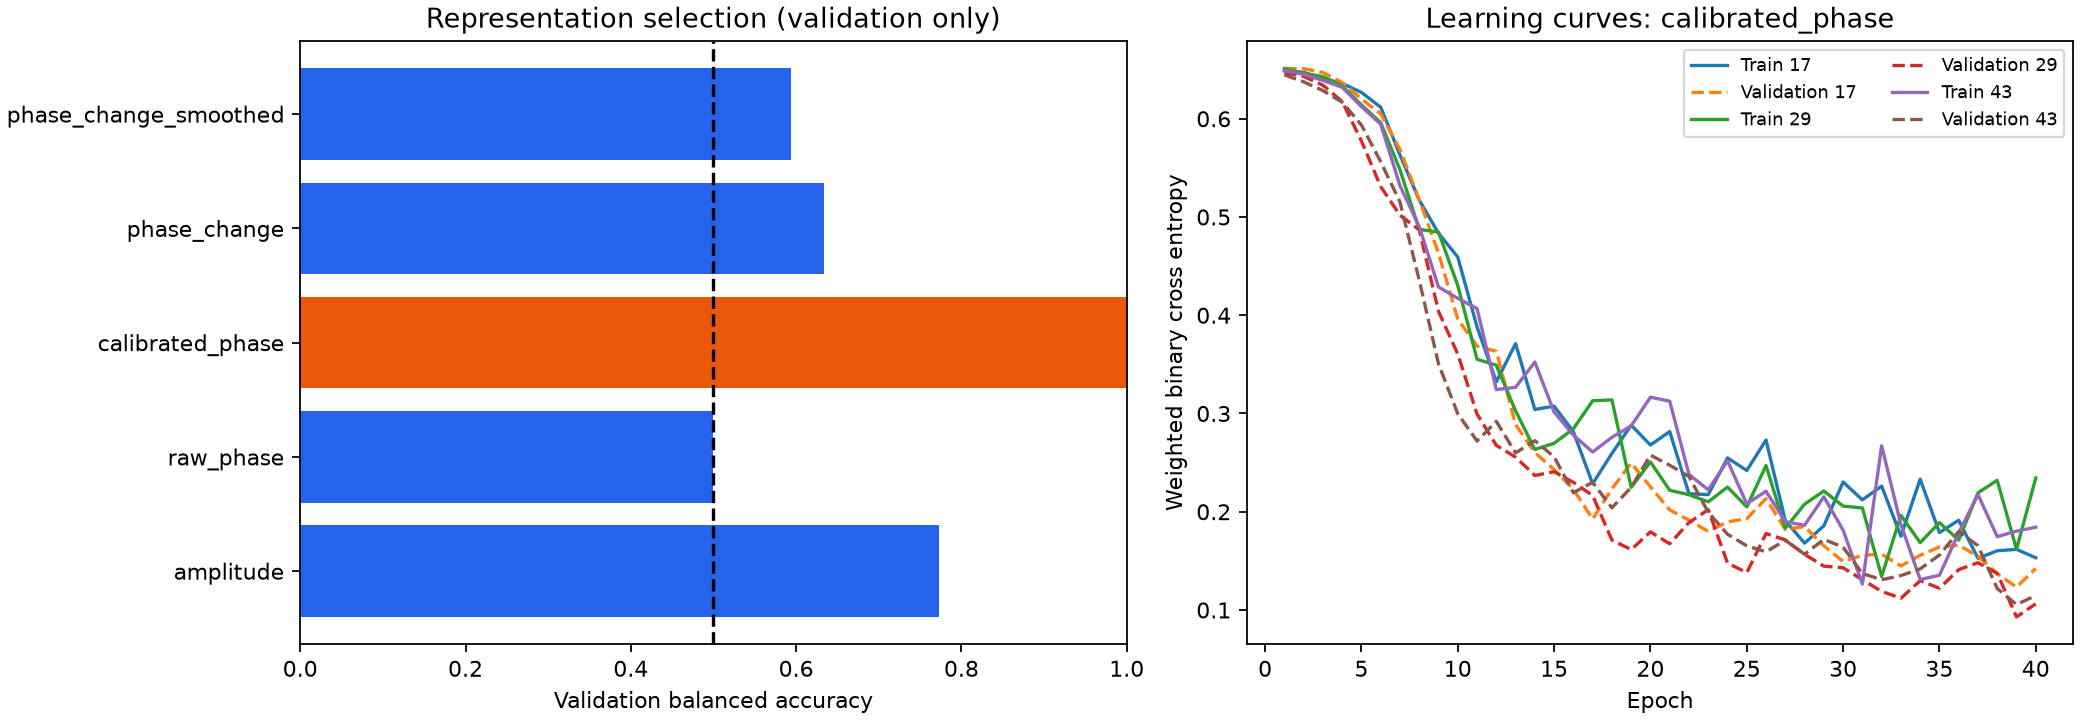

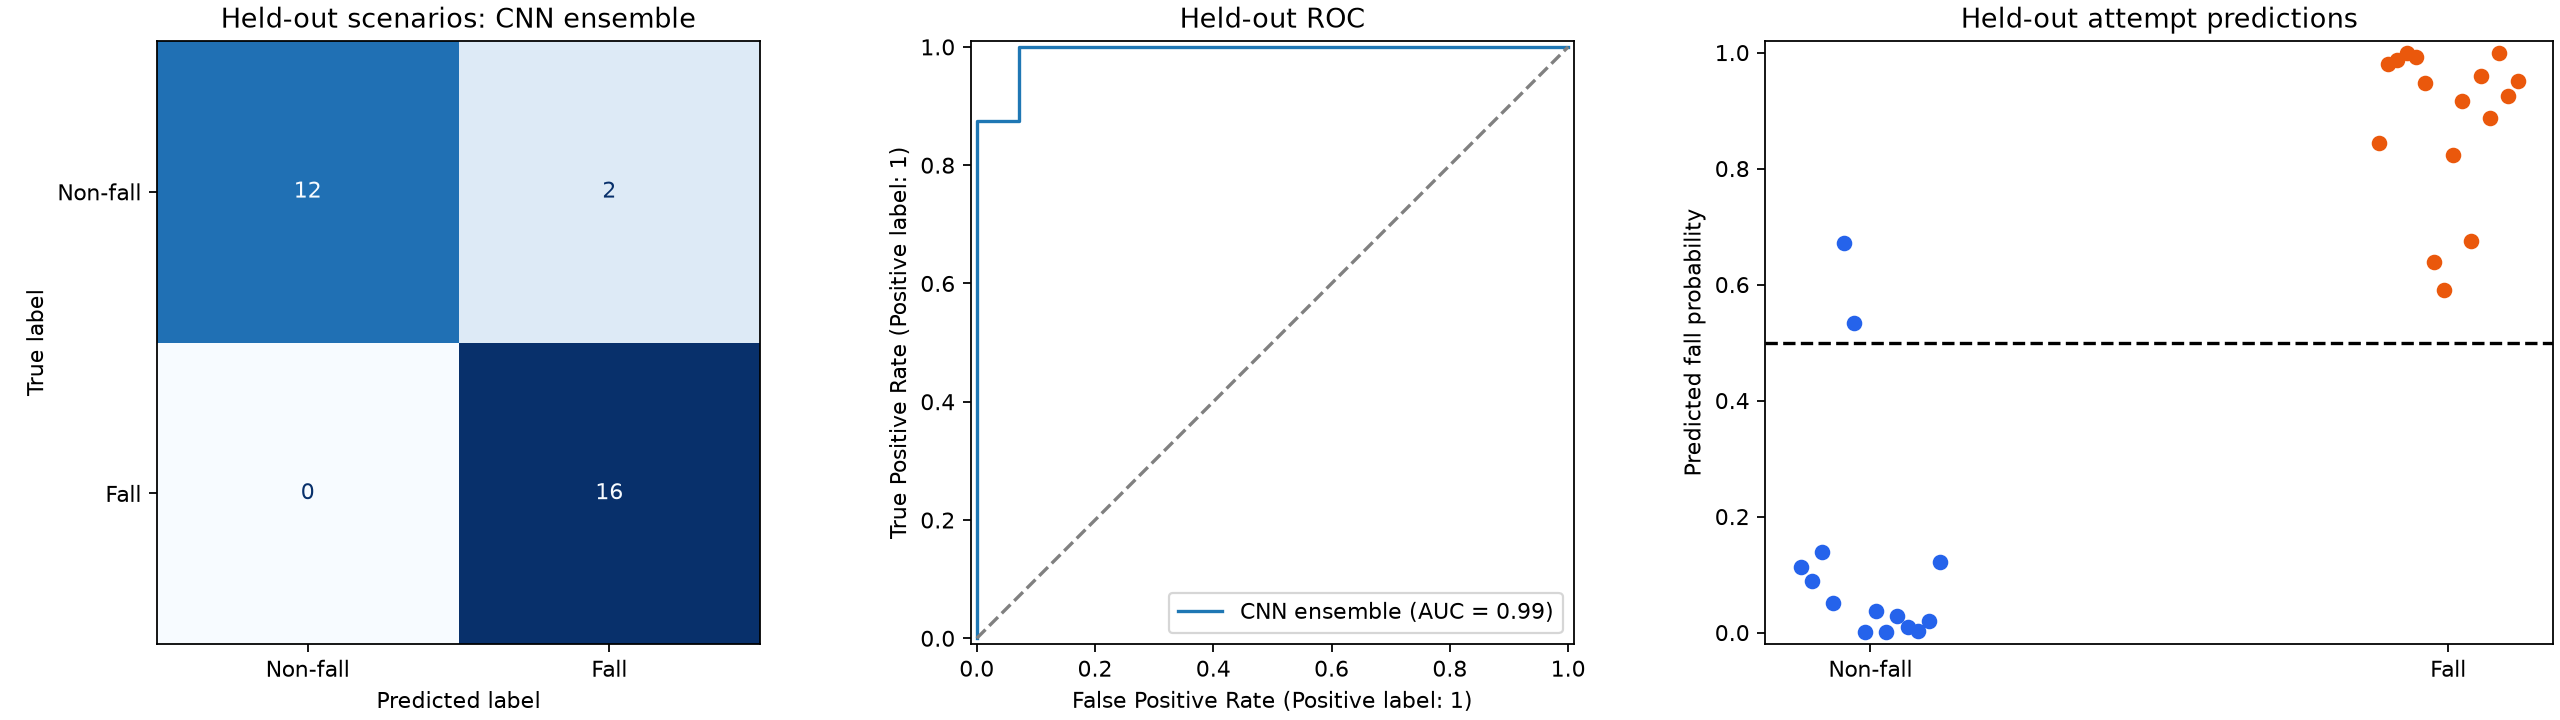

In [9]:
run_stage("evaluate")
if RERUN_PIPELINE:
    run_stage("report")

scores = json.loads((RESULTS / "test_metrics.json").read_text())
metrics = pd.DataFrame(scores["metrics"]).T
print(f"Test attempts: {scores['test_attempts']}; test scenarios: {scores['test_scenarios']}")
display(metrics[["accuracy", "balanced_accuracy", "fall_recall", "specificity", "fall_f1", "roc_auc", "tn", "fp", "fn", "tp"]])
show_figure("validation_and_learning.png")
show_figure("test_evaluation.png")

Inspect the errors by activity and attempt. Different seeds are different fits on the same test cohort, not independent cohorts.

In [10]:
predictions = pd.read_csv(RESULTS / "test_predictions.csv")
display(pd.read_csv(RESULTS / "test_activity_metrics.csv")[["activity", "n", "accuracy"]])
display(pd.read_csv(RESULTS / "test_seed_metrics.csv")[["seed", "accuracy", "balanced_accuracy", "fall_recall", "specificity"]])
display(predictions.loc[predictions["target"].ne(predictions["cnn_prediction"]),
    ["attempt_id", "label", "scenario_id", "cnn_probability", "cnn_prediction"]])

,activity,n,accuracy
0,sit_to_fall,4,1.000
1,sit_to_stand,2,1.000
2,sit_to_walk,6,1.000
3,stand_to_fall,6,1.000
4,walk_to_fall,6,1.000
5,walk_to_sit,6,0.667


,seed,accuracy,balanced_accuracy,fall_recall,specificity
0,17,0.933,0.929,1.000,0.857
1,29,0.933,0.933,0.938,0.929
2,43,0.933,0.929,1.000,0.857


,attempt_id,label,scenario_id,cnn_probability,cnn_prediction
20,115/01,walk_to_sit,walk-to-sit__start_back__end_left,0.672,1
21,116/01,walk_to_sit,walk-to-sit__start_back__end_left,0.533,1


## 7. What the result supports

The saved pilot selected calibrated phase and classified 28 of 30 held-out attempts correctly: 16 detected falls, 12 correctly rejected non-falls, and two false alarms. This supports within-session label discrimination despite the earlier visual overlap. It does not establish that the CNN specifically identified fall dynamics: static channel structure, recording order, and quality differences remain possible contributors. The missingness-only baseline also performed above chance.

All partitions share one participant, session, room, hardware, and collection protocol. Performance on new sessions or participants, continuous detection, timing shifts, and false alarms per hour remain untested. Resampling a test set with no missed falls gives a degenerate recall bootstrap interval; that does not establish perfect population sensitivity.

See the [full saved report](results/pilot_v1/REPORT.md), [implementation](modeling.py), and [preprocessing](data_pipeline.py) for details. The shifted-window idea discussed in the conversation remains a proposed next experiment.